# Check 1 — Physio summary realism validation

Two independent models check whether a single `physio_summary` text (generated by your LLM simulator) is realistic, by comparing it against your 2000 real physio summaries.

- **Method A** — fine-tune `distilgpt2` on real summaries, score new text by **perplexity** (how "surprised" the language model is by it). {NOT IMPLEMENTED HERE}
- **Method B** — embed summaries with `bge-small-en-v1.5`, and then perform classification using class-weighted loss computation.

A summary is trusted as realistic only if **both methods agree**. If they disagree, flag for manual review.


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

os.chdir("/content/drive/MyDrive/VA_checking/validate_phy_summary")
print(os.getcwd())

/content/drive/MyDrive/VA_checking/validate_phy_summary


## 0. Setup — install and import libraries

In [20]:
# Run once. Remove -q if you want to see install logs.
!pip install -q transformers datasets accelerate sentence-transformers scikit-learn pandas numpy torch


In [21]:
import re
import json
import numpy as np
import pandas as pd
import torch
from sklearn.model_selection import train_test_split
from sklearn.ensemble import IsolationForest

import matplotlib.pyplot as plt

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

print("Torch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())


Torch version: 2.11.0+cu128
CUDA available: True


**What this cell does:** imports everything we'll need across both methods, and fixes random seeds so your results are reproducible run to run. `CUDA available` tells you if fine-tuning will use GPU (much faster) or CPU (slower but fine for distilgpt2 at this data size).

## 1. Load and inspect the data

In [22]:
# Point this at your actual file
DATA_PATH = "/content/drive/MyDrive/all_physio_summaries.csv"

df = pd.read_csv(DATA_PATH)
print("Rows:", len(df))
print("Columns:", list(df.columns))
df.head(3)


Rows: 2016
Columns: ['physio_summary']


,physio_summary
0,"From the last 1 min, PR moved 69.0 to 70.0 bpm..."
1,"From the last 3 min, ACCEL moved 0.0 to 0.01 g..."
2,Last 6 min: ACCEL moved 0.0 to 0.02 g (rising)...


**What to check here:** row count should be ~2000. Confirm the text column is actually called `physio_summary` (rename below if it isn't). If row count is off, or there are extra unnamed columns, fix the CSV before continuing — everything downstream assumes one clean text column.

In [23]:
# Basic cleanup
df = df.rename(columns={df.columns[0]: "physio_summary"}) if "physio_summary" not in df.columns else df
df = df.dropna(subset=["physio_summary"]).reset_index(drop=True)
df["physio_summary"] = df["physio_summary"].astype(str).str.strip()

# Drop exact duplicates -- keep track of how many there were
n_before = len(df)
df = df.drop_duplicates(subset=["physio_summary"]).reset_index(drop=True)
print(f"Dropped {n_before - len(df)} exact duplicate summaries")
print("Final row count:", len(df))


Dropped 0 exact duplicate summaries
Final row count: 2016


**What this means:** exact duplicates don't help either model learn anything new, and can bias Method B's density estimate (a cluster of identical points looks artificially "normal"). Dropping them is safe and standard. If a large fraction got dropped (e.g. >10%), that's worth noting in your data-quality writeup — it suggests your rule-based generator repeats itself often.

## 2. Exploratory checks before training

window_min
1      88
2      25
3      23
4      32
5      22
6    1826
Name: count, dtype: int64


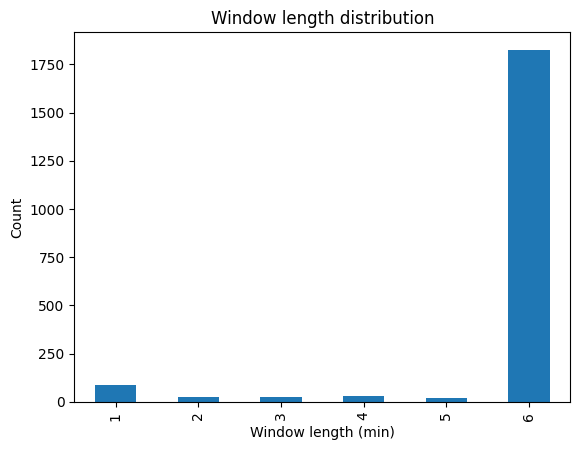

In [24]:
# Extract the reporting window length (1 min / 3 min / 6 min / etc.) from each summary
def extract_window(text):
    m = re.search(r'(?:last|Last|Across the last)\s+(\d+)\s*min', text)
    return int(m.group(1)) if m else None

df["window_min"] = df["physio_summary"].apply(extract_window)

window_counts = df["window_min"].value_counts().sort_index()
print(window_counts)

window_counts.plot(kind="bar", title="Window length distribution")
plt.xlabel("Window length (min)")
plt.ylabel("Count")
plt.show()


**What this means:** this tells you if window lengths (1/3/6 min etc.) are balanced or skewed. If one window length has very few examples (say under ~50), both models will have weak evidence for what "normal" looks like at that window length, and may flag realistic-but-rare-window summaries as anomalies just because they're underrepresented — not because they're actually wrong. If you see a strong skew, keep it in mind when interpreting later flags: double-check any flagged summary from a rare window length by hand before trusting the flag.

In [25]:
# Text length distribution -- sanity check for outlier-length summaries
df["char_len"] = df["physio_summary"].str.len()
df["char_len"].describe()


,char_len
count,2016.000000
mean,366.867560
std,44.272446
min,148.000000
25%,336.000000
50%,363.000000
75%,395.000000
max,557.000000


**What this means:** gives you min/max/mean/percentiles of summary length in characters. If max is wildly larger than the 75th percentile (e.g. 3x longer), open a few of those rows manually — could be a data export glitch (multiple turns concatenated into one cell), which you'd want to fix before training rather than let the model learn from broken rows.

# **Using Data Inflation and finetuned model with classification head**

In [43]:
# Correcting the far variant CSV (removing duplicates and Realistic summaries)
import pandas as pd

# 1. Load the original datasets
REALISTIC_PATH = "/content/drive/MyDrive/all_physio_summaries.csv"
FAR_VARIANT_PATH = "/content/drive/MyDrive/far_variant_data.csv" # or far_variant_data_2.csv

real_df = pd.read_csv(REALISTIC_PATH)
far_df = pd.read_csv(FAR_VARIANT_PATH)

print(f"Original Far Variant size: {len(far_df)}")

# 2. Drop Internal Duplicates in Far Variants
far_df_clean = far_df.drop_duplicates(subset=["physio_summary"]).copy()
print(f"After dropping internal duplicates: {len(far_df_clean)}")

# 3. Drop Overlap (Data Leakage) with Realistic Data
# Get all unique texts from the realistic dataset
realistic_texts = set(real_df["physio_summary"].dropna())

# Keep only the rows in Far Variants that are NOT in the realistic dataset
far_df_clean = far_df_clean[~far_df_clean["physio_summary"].isin(realistic_texts)].copy()
print(f"After dropping overlaps with Realistic data: {len(far_df_clean)}")

# 4. Save the clean dataset back to Drive
CLEAN_SAVE_PATH = "/content/drive/MyDrive/far_variant_data_clean.csv"
far_df_clean.to_csv(CLEAN_SAVE_PATH, index=False)
print(f"\nClean Far Variant dataset saved to: {CLEAN_SAVE_PATH}")

Original Far Variant size: 1850
After dropping internal duplicates: 1785
After dropping overlaps with Realistic data: 1500

Clean Far Variant dataset saved to: /content/drive/MyDrive/far_variant_data_clean.csv


In [46]:
# Loading the files and creating the balanced train, validation and test splits
# Inflating the data, so as to improve model accuracy
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.utils import resample

RANDOM_STATE = 42

# 1. LOAD DATA EXPLICITLY
REALISTIC_DATA_PATH = "/content/drive/MyDrive/all_physio_summaries.csv"
pos_df = pd.read_csv(REALISTIC_DATA_PATH)[["physio_summary"]].dropna().drop_duplicates().reset_index(drop=True)
pos_df["category"], pos_df["label"] = "Realistic", 1

# Load Far Variants
far_df = pd.read_csv("/content/drive/MyDrive/far_variant_data_clean.csv")[["physio_summary"]].dropna().drop_duplicates().reset_index(drop=True)
far_df["category"], far_df["label"] = "Far Variant", 0

# Load Close Variants
close_df = pd.read_csv("/content/drive/MyDrive/close_variant_impossible_point.csv")[["physio_summary"]].dropna().drop_duplicates().reset_index(drop=True)
close_df["category"], close_df["label"] = "Close Variant", 0

# 2. Extract Test Sets First (NO DUPLICATES ALLOWED IN TEST)
pos_test = pos_df.sample(n=100, random_state=RANDOM_STATE)
pos_rem = pos_df.drop(pos_test.index)

far_test = far_df.sample(n=50, random_state=RANDOM_STATE)
far_rem = far_df.drop(far_test.index)

close_test = close_df.sample(n=50, random_state=RANDOM_STATE)
close_rem = close_df.drop(close_test.index)

# 3. Split remaining into Train (80%) and Val (20%)
pos_train, pos_val = train_test_split(pos_rem, test_size=0.2, random_state=RANDOM_STATE)
far_train, far_val = train_test_split(far_rem, test_size=0.2, random_state=RANDOM_STATE)
close_train, close_val = train_test_split(close_rem, test_size=0.2, random_state=RANDOM_STATE)

# 4. INFLATION (Oversampling)
# Find the size of the largest class (Realistic) to set as our target
TARGET_TRAIN_SIZE = len(pos_train)
TARGET_VAL_SIZE = len(pos_val)

# Duplicate rows in Far and Close until they match the Realistic size
far_train_inf = resample(far_train, replace=True, n_samples=TARGET_TRAIN_SIZE, random_state=RANDOM_STATE)
close_train_inf = resample(close_train, replace=True, n_samples=TARGET_TRAIN_SIZE, random_state=RANDOM_STATE)

far_val_inf = resample(far_val, replace=True, n_samples=TARGET_VAL_SIZE, random_state=RANDOM_STATE)
close_val_inf = resample(close_val, replace=True, n_samples=TARGET_VAL_SIZE, random_state=RANDOM_STATE)

# 5. Merge and Shuffle
merged_train_df = pd.concat([pos_train, far_train_inf, close_train_inf]).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)
merged_val_df = pd.concat([pos_val, far_val_inf, close_val_inf]).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)
merged_test_df = pd.concat([pos_test, far_test, close_test]).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

# Save test set
merged_test_df.to_csv("./balanced_test_set_categorized.csv", index=False)

print("--- INFLATED DATASET SIZES ---")
print(f"Train label counts:\n{merged_train_df['label'].value_counts().to_string()}")
print(f"Val label counts:\n{merged_val_df['label'].value_counts().to_string()}")
print(f"Test label counts:\n{merged_test_df['label'].value_counts().to_string()}")

Far variant label counts:
label
0    1500
--- INFLATED DATASET SIZES ---
Train label counts:
label
0    3064
1    1532
Val label counts:
label
0    768
1    384
Test label counts:
label
1    100
0    100


In [47]:
# Fine tuning the model
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments

MODEL_NAME = "BAAI/bge-small-en-v1.5"
DRIVE_SAVE_PATH = "/content/drive/MyDrive/bge_inflated_classification_new"

# 1. Convert to Hugging Face Datasets
train_hf = Dataset.from_pandas(merged_train_df[["physio_summary", "label"]], preserve_index=False)
val_hf = Dataset.from_pandas(merged_val_df[["physio_summary", "label"]], preserve_index=False)

# 2. Load Model and Tokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)

def tokenize_fn(examples):
    return tokenizer(examples["physio_summary"], truncation=True, padding="max_length")

train_tokenized = train_hf.map(tokenize_fn, batched=True)
val_tokenized = val_hf.map(tokenize_fn, batched=True)

# 3. Train
training_args = TrainingArguments(
    output_dir="./bge_inflated_checkpoints",
    eval_strategy="epoch",
    logging_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=32,
    num_train_epochs=4,
    save_strategy="epoch",
    load_best_model_at_end=True,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_tokenized,
    eval_dataset=val_tokenized,
)

trainer.train()

# Save best model to Drive
trainer.save_model(DRIVE_SAVE_PATH)
tokenizer.save_pretrained(DRIVE_SAVE_PATH)
print(f"Model saved to: {DRIVE_SAVE_PATH}")

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `1`.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: BAAI/bge-small-en-v1.5
Key               | Status  | 
------------------+---------+-
classifier.bias   | MISSING | 
classifier.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Map:   0%|          | 0/4596 [00:00<?, ? examples/s]

Map:   0%|          | 0/1152 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss
1,0.636336,0.622616
2,0.560894,0.512143
3,0.484345,0.494199
4,0.453613,0.486164


... (2 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved to: /content/drive/MyDrive/bge_inflated_classification_new


In [48]:
# Running the saved finetuned model on the balanced test set
import pandas as pd
import numpy as np
from scipy.special import softmax
from sklearn.metrics import classification_report, confusion_matrix
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer
from datasets import Dataset

# ============================================================
# Evaluate the Inflated Sequence Classifier
# ============================================================
DRIVE_SAVE_PATH = "/content/drive/MyDrive/bge_inflated_classification_new"
TEST_SET_PATH = "./balanced_test_set_categorized.csv"
RESULTS_SAVE_PATH = "./inflated_test_results.csv"

print(f"Loading inflated model and tokenizer from: {DRIVE_SAVE_PATH}")
tokenizer = AutoTokenizer.from_pretrained(DRIVE_SAVE_PATH)
model = AutoModelForSequenceClassification.from_pretrained(DRIVE_SAVE_PATH)

# Load categorized test set
test_df = pd.read_csv(TEST_SET_PATH)
test_hf = Dataset.from_pandas(test_df[["physio_summary", "label"]], preserve_index=False)

# Tokenize
def tokenize_fn(examples):
    return tokenizer(
        examples["physio_summary"],
        truncation=True,
        padding="max_length"
    )

test_tokenized = test_hf.map(tokenize_fn, batched=True)

# Initialize a lightweight Trainer strictly for inference
inference_trainer = Trainer(model=model)

print("Running predictions on the test set...")
predictions = inference_trainer.predict(test_tokenized)
logits = predictions.predictions
probs = softmax(logits, axis=1)

# Extract probabilities and predicted classes
test_df["prob_unrealistic"] = probs[:, 0]
test_df["prob_realistic"] = probs[:, 1]
test_df["predicted_label"] = np.argmax(logits, axis=1)

# Format flag for the final table (True = flagged as Unrealistic)
test_df["flagged_by_Inflated"] = test_df["predicted_label"] == 0

# ============================================================
# Performance Metrics
# ============================================================
print("\n" + "=" * 60)
print("INFLATED CLASSIFIER: TEST SET METRICS")
print("=" * 60)

print("\nClassification Report:")
print(classification_report(
    test_df["label"],
    test_df["predicted_label"],
    target_names=["Unrealistic (Class 0)", "Realistic (Class 1)"]
))

print("\nConfusion Matrix:")
cm = confusion_matrix(test_df["label"], test_df["predicted_label"])
print(f"True Negatives (Correctly identified Unrealistic):  {cm[0][0]}")
print(f"False Positives (Unrealistic flagged as Realistic): {cm[0][1]}")
print(f"False Negatives (Realistic flagged as Unrealistic): {cm[1][0]}")
print(f"True Positives (Correctly identified Realistic):    {cm[1][1]}")

# ============================================================
# Save Results for the Category Table
# ============================================================
test_df.to_csv(RESULTS_SAVE_PATH, index=False)
print(f"\nSaved predictions for category breakdown to: {RESULTS_SAVE_PATH}")

Loading inflated model and tokenizer from: /content/drive/MyDrive/bge_inflated_classification_new


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Map:   0%|          | 0/200 [00:00<?, ? examples/s]

Running predictions on the test set...



INFLATED CLASSIFIER: TEST SET METRICS

Classification Report:
                       precision    recall  f1-score   support

Unrealistic (Class 0)       0.91      0.78      0.84       100
  Realistic (Class 1)       0.81      0.92      0.86       100

             accuracy                           0.85       200
            macro avg       0.86      0.85      0.85       200
         weighted avg       0.86      0.85      0.85       200


Confusion Matrix:
True Negatives (Correctly identified Unrealistic):  78
False Positives (Unrealistic flagged as Realistic): 22
False Negatives (Realistic flagged as Unrealistic): 8
True Positives (Correctly identified Realistic):    92

Saved predictions for category breakdown to: ./inflated_test_results.csv


In [49]:
# ============================================================
# FINAL RESULTS TABLE — 3 CATEGORY BREAKDOWN
# ============================================================
import pandas as pd
from IPython.display import display

RESULTS_PATH = "./inflated_test_results.csv"
df = pd.read_csv(RESULTS_PATH)

# Find flag columns
flag_columns = [col for col in df.columns if col.lower().startswith("flagged_by_")]

if not flag_columns:
    raise ValueError("No 'flagged_by_' columns found.")

# The categories will now explicitly be: ['Close Variant', 'Far Variant', 'Realistic']
categories = sorted(df["category"].dropna().astype(str).unique())
rows = []

for flag_col in flag_columns:
    method = flag_col.replace("flagged_by_", "")

    # Map to booleans
    flag_values = df[flag_col].astype(str).str.strip().str.lower().map({
        "true": True, "false": False, "1": True, "0": False
    })

    for flag in [True, False]:
        row = {"Method": method, "Flagged as Unrealistic": flag}

        # Calculate counts per specific category (Close, Far, Realistic)
        for category in categories:
            mask = (df["category"].astype(str) == category) & (flag_values == flag)
            row[category] = int(mask.sum())

        rows.append(row)

results_table = pd.DataFrame(rows)

print("\n" + "=" * 100)
print("METHOD-WISE RESULTS BY CATEGORY (CLOSE vs FAR vs REALISTIC)")
print("=" * 100)

display(results_table)
results_table.to_csv("./category_breakdown_results.csv", index=False)


METHOD-WISE RESULTS BY CATEGORY (CLOSE vs FAR vs REALISTIC)


,Method,Flagged as Unrealistic,Close Variant,Far Variant,Realistic
0,Inflated,True,39,39,8
1,Inflated,False,11,11,92


# Below are the CELLS with the initial implementations (kept for reference)

## 4. Method A — fine-tune `distilgpt2`, score by perplexity

Perplexity measures how "surprised" a language model is by a piece of text. Low perplexity = the text follows patterns the model has seen many times (looks normal). High perplexity = unusual word combinations/structure (looks unlike your real data).

In [ ]:
from transformers import GPT2LMHeadModel, GPT2TokenizerFast, DataCollatorForLanguageModeling, Trainer, TrainingArguments
from datasets import Dataset

MODEL_NAME = "distilgpt2"

tokenizer = GPT2TokenizerFast.from_pretrained(MODEL_NAME)
tokenizer.pad_token = tokenizer.eos_token  # distilgpt2 has no pad token by default

model = GPT2LMHeadModel.from_pretrained(MODEL_NAME)
print("Model loaded:", MODEL_NAME)
print("Parameters:", sum(p.numel() for p in model.parameters()))


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  353MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Model loaded: distilgpt2
Parameters: 81912576


In [ ]:
def tokenize_fn(batch):
    return tokenizer(
        batch["physio_summary"],
        truncation=True,
        max_length=256,
        padding="max_length",
    )

train_ds = Dataset.from_pandas(train_df[["physio_summary"]])
val_ds = Dataset.from_pandas(val_df[["physio_summary"]])

train_ds = train_ds.map(tokenize_fn, batched=True, remove_columns=["physio_summary"])
val_ds = val_ds.map(tokenize_fn, batched=True, remove_columns=["physio_summary"])

data_collator = DataCollatorForLanguageModeling(tokenizer=tokenizer, mlm=False)


Map:   0%|          | 0/756 [00:00<?, ? examples/s]

Map:   0%|          | 0/190 [00:00<?, ? examples/s]

**What this does:** converts each summary into token IDs distilgpt2 can process, padded/truncated to 256 tokens (plenty for your summary length). `mlm=False` tells the collator this is causal (left-to-right) language modeling, not masked LM — correct setting for GPT-2 style fine-tuning.

In [ ]:
import inspect

# Different transformers versions accept slightly different TrainingArguments
# field names (e.g. eval_strategy vs evaluation_strategy) and some fields like
# overwrite_output_dir have been dropped in newer versions. This builds the
# kwargs dict dynamically and only keeps arguments your installed version
# actually accepts, so the same notebook runs across versions.

desired_args = {
    "output_dir": "./distilgpt2-physio",
    "overwrite_output_dir": True,
    "num_train_epochs": 5,
    "per_device_train_batch_size": 8,
    "per_device_eval_batch_size": 8,
    "eval_strategy": "epoch",
    "evaluation_strategy": "epoch",  # older name, kept as fallback
    "save_strategy": "epoch",
    "save_total_limit": 1,
    "logging_steps": 50,
    "learning_rate": 5e-5,
    "weight_decay": 0.01,
    "load_best_model_at_end": True,
    "metric_for_best_model": "eval_loss",
    "report_to": "none",
}

accepted_params = set(inspect.signature(TrainingArguments.__init__).parameters.keys())
final_args = {k: v for k, v in desired_args.items() if k in accepted_params}

dropped = set(desired_args.keys()) - set(final_args.keys())
if dropped:
    print("Note: your transformers version doesn't accept these args, skipping:", dropped)

training_args = TrainingArguments(**final_args)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=data_collator,
)

trainer.train()


Note: your transformers version doesn't accept these args, skipping: {'overwrite_output_dir', 'evaluation_strategy'}


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Epoch,Training Loss,Validation Loss


**What to watch during training:** `eval_loss` printed each epoch should generally decrease then flatten. If `eval_loss` starts *increasing* while `train_loss` keeps dropping, that's overfitting — `load_best_model_at_end=True` protects you by automatically keeping the checkpoint with the lowest validation loss, not necessarily the last one.

In [ ]:
model.eval()
model.to("cuda" if torch.cuda.is_available() else "cpu")
device = next(model.parameters()).device

@torch.no_grad()
def compute_perplexity(text: str) -> float:
    """Lower = more realistic/expected given the fine-tuned model. Higher = unusual."""
    inputs = tokenizer(text, return_tensors="pt", truncation=True, max_length=256).to(device)
    outputs = model(**inputs, labels=inputs["input_ids"])
    loss = outputs.loss  # average negative log-likelihood per token
    return float(torch.exp(loss))

# Sanity check on one real example
sample_text = val_df["physio_summary"].iloc[0]
print("Sample text:", sample_text[:120], "...")
print("Perplexity:", compute_perplexity(sample_text))


**What this means:** perplexity is roughly "the model was as surprised as if it had to guess uniformly among N words at each step." A perplexity of 5 means the model was fairly confident; a perplexity of 500 means it was very confused by the text. There's no universal "good" number — what matters is how a *new* summary's perplexity compares to your *real validation set's* perplexity distribution, which is what the next cell establishes.

In [ ]:
val_perplexities = val_df["physio_summary"].apply(compute_perplexity)

print(val_perplexities.describe())

threshold_A = val_perplexities.quantile(0.95)
print(f"\nMethod A threshold (95th percentile of real validation perplexity): {threshold_A:.2f}")

val_perplexities.hist(bins=30)
plt.axvline(threshold_A, color="red", linestyle="--", label="95th percentile threshold")
plt.xlabel("Perplexity")
plt.ylabel("Count")
plt.title("Perplexity distribution -- real validation summaries")
plt.legend()
plt.show()


**What this means:** this is your real, held-out data's own perplexity spread — the "ruler" you'll measure new summaries against. `threshold_A` is set so that 95% of your genuine real summaries fall below it. Any new summary scoring *above* this threshold is more unusual than 95% of your real data — flag it as suspicious under Method A. You can loosen (99th percentile, fewer false flags) or tighten (90th percentile, catches more but more false positives) depending on how strict you want to be.

## 5. Method B — MiniLM embeddings + Isolation Forest

This method ignores fine-grained wording and instead checks: does this summary's overall *meaning* sit inside the cloud of real summaries in embedding space, or off on its own?

In [ ]:
from sentence_transformers import SentenceTransformer

embedder = SentenceTransformer("all-MiniLM-L6-v2")

train_embeddings = embedder.encode(train_df["physio_summary"].tolist(), show_progress_bar=True)
val_embeddings = embedder.encode(val_df["physio_summary"].tolist(), show_progress_bar=True)

print("Embedding shape:", train_embeddings.shape)


**What this does:** turns each summary into a 384-number vector capturing its overall meaning. `train_embeddings.shape` should print `(N, 384)` where N is your training set size -- confirms it ran correctly. No fine-tuning happens here, MiniLM is used as-is.

In [ ]:
iso_forest = IsolationForest(
    n_estimators=200,
    contamination=0.05,   # assume ~5% of even real data is at the "edge" of normal
    random_state=RANDOM_STATE,
)
iso_forest.fit(train_embeddings)

# decision_function: higher = more normal, lower/negative = more anomalous
val_scores = iso_forest.decision_function(val_embeddings)

print(pd.Series(val_scores).describe())

threshold_B = np.quantile(val_scores, 0.05)  # bottom 5% of real val scores
print(f"\nMethod B threshold (5th percentile of real validation anomaly score): {threshold_B:.4f}")

pd.Series(val_scores).hist(bins=30)
plt.axvline(threshold_B, color="red", linestyle="--", label="5th percentile threshold")
plt.xlabel("Isolation Forest decision score (higher = more normal)")
plt.ylabel("Count")
plt.title("Anomaly score distribution -- real validation summaries")
plt.show()


**What this means:** `decision_function` gives a normality score per summary — higher means it sits comfortably inside the dense region of real summaries, lower (especially negative) means it's isolated/unusual in embedding space. `threshold_B` marks the bottom 5% of your real validation data's own scores. A new summary scoring *below* this threshold is more isolated than 95% of your real data — flag it under Method B.

## 6. Combine both methods and score new (LLM-simulated) summaries

In [ ]:
def check_physio_summary(text: str) -> dict:
    """
    Runs both realism checks on a single physio_summary string.
    Returns a dict with both raw scores and a combined verdict.
    """
    ppl = compute_perplexity(text)
    flagged_A = ppl > threshold_A

    emb = embedder.encode([text])
    score_B = iso_forest.decision_function(emb)[0]
    flagged_B = score_B < threshold_B

    if flagged_A and flagged_B:
        verdict = "unrealistic (high confidence)"
    elif flagged_A or flagged_B:
        verdict = "review manually (methods disagree)"
    else:
        verdict = "realistic"

    return {
        "text": text,
        "perplexity": ppl,
        "flagged_by_A": bool(flagged_A),
        "isolation_score": float(score_B),
        "flagged_by_B": bool(flagged_B),
        "verdict": verdict,
    }


**What this function returns, field by field:**
- `perplexity` / `flagged_by_A` — Method A's raw score and whether it exceeded the real-data threshold.
- `isolation_score` / `flagged_by_B` — Method B's raw score and whether it fell below the real-data threshold.
- `verdict` — the combined call:
  - **"realistic"** — neither method flagged it, trust it.
  - **"review manually"** — the two methods disagree, meaning it's borderline. Read it yourself before deciding.
  - **"unrealistic (high confidence)"** — both methods independently found it unusual, strong signal it's a bad/fabricated summary.

In [ ]:
# Try it on a few real held-out examples (should mostly come back "realistic")
print("--- Real validation examples ---")
for text in val_df["physio_summary"].sample(3, random_state=RANDOM_STATE):
    result = check_physio_summary(text)
    print(result["verdict"], "| perplexity:", round(result["perplexity"], 2), "| isolation_score:", round(result["isolation_score"], 4))

# Try it on new LLM-simulated summaries -- replace with your actual generated text
new_summaries = [
    "PASTE A NEW LLM-GENERATED PHYSIO SUMMARY HERE",
]

print("\n--- New LLM-simulated summaries ---")
for text in new_summaries:
    result = check_physio_summary(text)
    print(json.dumps(result, indent=2))


**What to look for:** the real validation examples should mostly print `realistic` — if many of them get flagged, your thresholds are too strict (lower the percentile cutoffs in Sections 4/5) or something went wrong upstream. For your actual LLM-simulated summaries, this is the real test — run your full batch of generated summaries through `check_physio_summary` (loop over a DataFrame column) and tally how many land in each verdict bucket.

## 7. Batch-score a full file of new/simulated summaries

In [ ]:
# Point this at your LLM-simulated summaries file
NEW_DATA_PATH = "simulated_physio_summaries.csv"

new_df = pd.read_csv(NEW_DATA_PATH)
results = new_df["physio_summary"].apply(check_physio_summary).apply(pd.Series)

new_df = pd.concat([new_df, results.drop(columns=["text"])], axis=1)

print(new_df["verdict"].value_counts())
new_df.to_csv("physio_summary_realism_results.csv", index=False)
print("\nSaved: physio_summary_realism_results.csv")


**What this means:** `value_counts()` gives you the headline number — e.g. "1400 realistic, 350 review manually, 250 unrealistic (high confidence)". The saved CSV has one row per summary with both raw scores and the verdict, so you can filter to the "unrealistic" and "review manually" rows and inspect them directly, or feed the confidently-realistic ones forward into your Check 2 (text-physio-response alignment) pipeline.